<center><h1>zheng_yiyi_HW4</h1></center>
<br>
<br>

Name: yiyi zheng
<br>
Github Username: yiyizheng111
<br>
USC ID: 7092417109


# Question 8: Predicting Student Final Grades with Linear Regression

## (a) Data Exploration and Pre-processing

### (i) Import Dataset

First, I import the dataset and check the data.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the student data
df = pd.read_csv("data/student/student-mat.csv", sep=";")

# Check the dataset
print("Dataset shape:", df.shape)

# Show the first 5 rows
df.head()


Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Question 8(a)(ii)

In [3]:

# Select the features
columns = [
    "age", "studytime", "schoolsup", "goout",
    "Dalc", "Walc", "health", "absences", "G3"
]

student_df = df[columns].copy()

# Change yes/no to 1/0
student_df["schoolsup"] = student_df["schoolsup"].map({
    "yes": 1,
    "no": 0
})

# Calculate average alcohol consumption
student_df["alc"] = (student_df["Dalc"] + student_df["Walc"]) / 2

# Remove alcohol columns
student_df = student_df.drop(columns=["Dalc", "Walc"])

# Check the new dataset
print("New dataset shape:", student_df.shape)
print("\nMissing values:")
print(student_df.isnull().sum())

# Show the first 5 rows
student_df.head()


New dataset shape: (395, 8)

Missing values:
age          0
studytime    0
schoolsup    0
goout        0
health       0
absences     0
G3           0
alc          0
dtype: int64


,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


Question 8(a)(iii)

In [4]:

# Using the IQR methodn to find outliers

X = student_df.drop(columns=["G3"])

outlier_results = []

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Count values outside the IQR range
    outliers = ((X[col] < lower) | (X[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers": outliers
    })

outlier_df = pd.DataFrame(outlier_results)

print("Number of outliers for each feature:")
outlier_df


Number of outliers for each feature:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,age,16.0,18.0,2.0,13.00,21.00,1
1,studytime,1.0,2.0,1.0,-0.50,3.50,27
2,schoolsup,0.0,0.0,0.0,0.00,0.00,51
3,goout,2.0,4.0,2.0,-1.00,7.00,0
4,health,3.0,5.0,2.0,0.00,8.00,0
5,absences,0.0,8.0,8.0,-12.00,20.00,15
6,alc,1.0,2.5,1.5,-1.25,4.75,9


I used the IQR method to find outliers for each independent variable.

From the results, schoolsup has the most outliers (51). Goout and health have no outliers.

For schoolsup, the IQR is 0 because most values are 0. So the values of 1 are counted as outliers, but they are still valid data.

Question 8(a)(iv)

Explained variance:
PC1: 0.2368
PC2: 0.1714


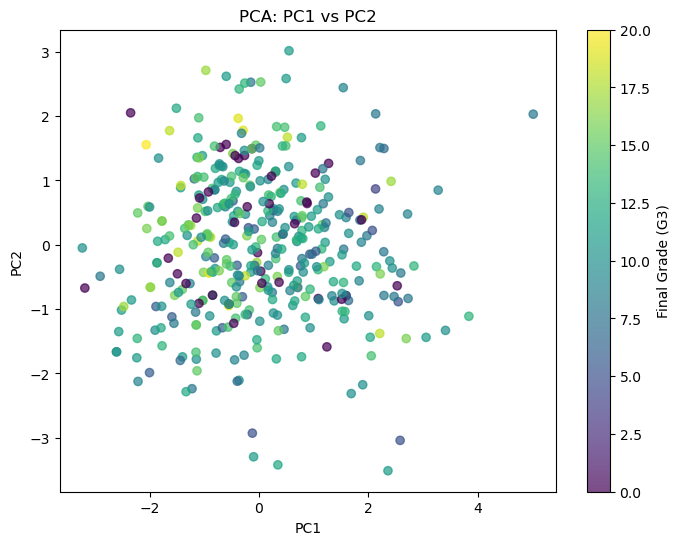


PCA Component Loadings:
              PC1     PC2
age        0.3819  0.5893
studytime -0.3297  0.3857
schoolsup -0.2482 -0.4642
goout      0.4938 -0.1396
health     0.0805 -0.4009
absences   0.2801  0.1828
alc        0.5959 -0.2737

Top 3 features for PC1:
alc      0.595871
goout    0.493755
age      0.381940
Name: PC1, dtype: float64

Top 3 features for PC2:
age          0.589260
schoolsup    0.464202
health       0.400925
Name: PC2, dtype: float64


In [5]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate the features and target
X = student_df.drop(columns=["G3"])
y = student_df["G3"]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Show explained variance
print("Explained variance:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

# Plot PC1 and PC2
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(label="Final Grade (G3)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 vs PC2")
plt.show()

# Show component loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

print("\nPCA Component Loadings:")
print(loadings.round(4))

# Find the most important features
print("\nTop 3 features for PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(3))

print("\nTop 3 features for PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(3))


I standardized the independent variables and used PCA to reduce the data to two components.

PC1 explains 23.68% of the variance. PC2 explains 17.14% of the variance. They explain 40.82% of the total variance together.

From the loadings, alc, goout, and age contribute the most to PC1. The most important features are age, schoolsup, and health,for Pc2.

In the scatterplot, students with different G3 grades are mixed together. I cannot see a clear separation between students with high and low grades.

So, PC1 and PC2 can show some patterns in the features, but they do not clearly separate students by their final grades.

Question 8(b)(i)

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the data into training and testing sets
X = student_df.drop(columns=["G3"])
y = student_df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=552
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

# Check the data size
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check the standardized training data
X_train_scaled.head()


Training data: (316, 7)
Testing data: (79, 7)

Training target: (316,)
Testing target: (79,)


,age,studytime,schoolsup,goout,health,absences,alc
125,-1.323751,-1.290019,2.422719,1.724515,1.024259,-0.689096,0.668590
99,-0.543331,1.073147,2.422719,1.724515,-0.401582,-0.689096,-0.877321
163,0.237090,-1.290019,-0.412759,-0.113417,-1.114502,-0.445250,0.668590
128,1.017510,-1.290019,-0.412759,-0.113417,0.311339,-0.689096,-0.362017
55,-0.543331,-0.108436,-0.412759,0.805549,-1.114502,0.286287,-0.877321


I split the dataset into 80% training data and 20% testing data, using random_state = 552.

Then I standardized the independent variables using the training data. I used the same scaler for the test data to avoid data leakage.

Question 8(b)(ii)

In [7]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Build three regression models
linear_model = LinearRegression()
ridge_model = Ridge(alpha=0.1)
lasso_model = Lasso(alpha=0.1, max_iter=10000)

# Put models together
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

# Train the models
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(name, "trained successfully")

print("\nNumber of training samples:", len(y_train))


Linear Regression trained successfully
Ridge Regression trained successfully
Lasso Regression trained successfully

Number of training samples: 316


Question 8(b)(iii)

In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the three models on test data
results = []

for name, model in models.items():

    # Predict final grades
    y_pred = model.predict(X_test_scaled)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Show the comparison table
results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
print(results_df.round(4).to_string(index=False))

# Find the best model for each metric
best_mae = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_rmse = results_df.loc[results_df["RMSE"].idxmin(), "Model"]
best_r2 = results_df.loc[results_df["R2"].idxmax(), "Model"]

print("\nBest model for MAE:", best_mae)
print("Best model for RMSE:", best_rmse)
print("Best model for R2:", best_r2)


Model Evaluation Results:
            Model    MAE   RMSE     R2
Linear Regression 3.4180 4.7558 0.0282
 Ridge Regression 3.4181 4.7559 0.0282
 Lasso Regression 3.4473 4.7946 0.0123

Best model for MAE: Linear Regression
Best model for RMSE: Linear Regression
Best model for R2: Linear Regression


I tested all three models on the test data and calculated MAE, RMSE, and R².

Linear Regression had the lowest MAE (3.4180) and RMSE (4.7558). It also had the highest R² (0.0282).

Ridge Regression had almost the same results as Linear Regression. Lasso Regression performed slightly worse.

Thus, Linear Regression was the best model based on these three metrics.

8(b)(iv)

The R² values are very low for all three models.

Linear Regression and Ridge Regression both had an R² of 0.0282. This means they explain about 2.82% of the variation in G3 on the test set.

Lasso Regression had an R² of 0.0123, which means it explains only about 1.23%.

I think these results show that the selected features are not enough to predict students' final grades very well. There may be other important features that are not included in our models.

Question 8(b)(v)

In [9]:

# Compare coefficients from the three models

coef_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Linear Regression": linear_model.coef_,
    "Ridge Regression": ridge_model.coef_,
    "Lasso Regression": lasso_model.coef_
})

print("Regression Coefficients:")
print(coef_df.round(4).to_string(index=False))

# Show intercepts
print("\nIntercepts:")
for name, model in models.items():
    print(name, ":", round(model.intercept_, 4))


Regression Coefficients:
  Feature  Linear Regression  Ridge Regression  Lasso Regression
      age            -0.7853           -0.7850           -0.6309
studytime             0.4491            0.4490            0.3513
schoolsup            -0.7178           -0.7175           -0.5701
    goout            -0.5701           -0.5699           -0.4777
   health            -0.2458           -0.2457           -0.1419
 absences             0.1978            0.1977            0.0708
      alc             0.0363            0.0361           -0.0000

Intercepts:
Linear Regression : 10.6139
Ridge Regression : 10.6139
Lasso Regression : 10.6139


I compared the coefficients from the three regression models.

Linear Regression and Ridge Regression have almost the same coefficients. Lasso Regression has smaller coefficients because of regularization.

Also, Lasso makes the coefficient of alc equal to zero.

8(b)(vi)

From the coefficients, age, schoolsup, goout, and health have negative relationships with G3.

Age has a coefficient of -0.7853. We can say older students have lower predicted grades in this model. Students with school support and students who go out more also have lower predicted grades. Health has a smaller negative coefficient.

Studytime has a positive coefficient of 0.4491. More study time is related to higher predicted grades.

Absences also has a small positive coefficient of 0.1978. However, this does not mean missing more classes will improve grades. It is only the relationship shown by this model.

Alc has a very small positive coefficient in Linear Regression. Lasso makes it zero, so alc may not be very useful for prediction in this model.

Since the features are standardized, the coefficients show the change in predicted G3 for a one standard deviation increase in each feature, while keeping other features the same.

8(b)(vii)

Ridge uses L2 regularization, which makes the coefficients smaller. Lasso uses L1 regularization, which can make some coefficients equal to zero.

From the results, Linear Regression and Ridge have almost the same performance. Lasso has slightly higher MAE and RMSE, and a lower R².

Lasso also makes the coefficient of alc equal to zero. It removes this feature from the model.

In this dataset, regularization did not improve the test results when alpha = 0.1.

All three models have very low R² values. I think the selected features do not explain students' final grades very well. We may need more useful features to improve the prediction.

8(b)(viii)

When alpha increases, the regularization becomes stronger, and the coefficients become smaller. In Lasso, some coefficients may also become zero.

For the training data, stronger regularization may increase RMSE and R² may decrease.

For the test data, a larger alpha may improve the performance by reducing overfitting. However, if alpha is too large, the model may underfit the data. Then MAE and RMSE may increase, and R² may decrease.

Thus, increasing alpha does not always improve the model. We need to choose a suitable alpha.

Question 8(b)(ix)

I think we can add more useful features to improve the model performance.

We can add G1 and G2, which are students' previous grades. These may help predict G3 better if they are available before the prediction.

And, we can create interaction features, such as studytime and absences, to see how they affect grades together.

Also, we can try polynomial features because some relationships may not be linear，and we can use log transformation for absences to reduce the effect of large values.

Since the R² values of our models are very low, I think these methods may help improve the prediction. But we still need to test them to see if they really work.